# XEMM Basic Demo

Load tabulated material data, interpolate refractive index values, then evaluate the same material model with `jax.jit` and differentiate it with `jax.grad`.

In [1]:
import jax
import jax.numpy as jp
import matplotlib.pyplot as plt

from xmdm import Material

In [2]:

Material.avail()

# xemm.avail()


['a-Si',
 'Ag',
 'Al',
 'Al2O3',
 'AlSb',
 'Au',
 'BP',
 'C',
 'CdS',
 'CdSe',
 'CdTe',
 'Cr',
 'Cu',
 'Fe',
 'GaAs',
 'GaN',
 'GaP',
 'GaSb',
 'Ge',
 'H2O',
 'In',
 'InAs',
 'InP',
 'InSb',
 'LC',
 'Ni',
 'Pd',
 'PDMS',
 'Pt',
 'Rh',
 'Si',
 'Si3N4',
 'SiC',
 'SiO2',
 'Sn',
 'Ta',
 'Ti',
 'TiN',
 'TiO2',
 'V',
 'VO2',
 'W',
 'ZnO',
 'ZnS',
 'ZnSe',
 'ZnTe']

E1031 17:09:37.621196 1899056 cuda_executor.cc:1365] [0] Failed to allocate device memory of 6.00GiB (6442450944 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:230
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:487

E1031 17:09:37.622064 1899056 cuda_executor.cc:1365] [0] Failed to allocate device memory of 5.40GiB (5798205440 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:230
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:487

E1031 17:09:37.622899 1899056 cuda_executor.cc:1365] [0] Failed to allocate device memory of 4.86GiB (5218384896 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=

  importing... Silver (Ag)


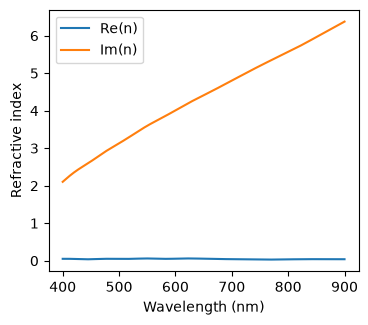

In [3]:
material = Material.from_db('Ag/Johnson', unit='nm', kind='n')
wavelengths = jp.linspace(400.0, 900.0, 201)
refractive_index = material.interp(wavelengths, unit='nm', kind='n', interp='cubic')

plt.figure(figsize=(4.0,3.4))
plt.plot(wavelengths, jp.real(refractive_index), label='Re(n)')
plt.plot(wavelengths, jp.imag(refractive_index), label='Im(n)')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Refractive index')
plt.legend()
plt.show()

In [4]:
@jax.jit
def permittivity_at(wavelength_nm):
  return material.interp(
    wavelength_nm,
    unit='nm',
    kind='e',
    interp='linear',
    extrap=False,
  )

wavelength_nm = 500.0
permittivity = permittivity_at(wavelength_nm)
permittivity_gradient = jax.grad(
  lambda value: jp.real(permittivity_at(value))
)(wavelength_nm)

print(f'epsilon({wavelength_nm:.0f} nm) = {permittivity}')
print(f'd Re(epsilon) / d wavelength = {permittivity_gradient}')

epsilon(500 nm) = (-9.799934387207031+0.31308838725090027j)
d Re(epsilon) / d wavelength = -0.05785870924592018


  importing... Germanium (Ge), Aspnes & Studna


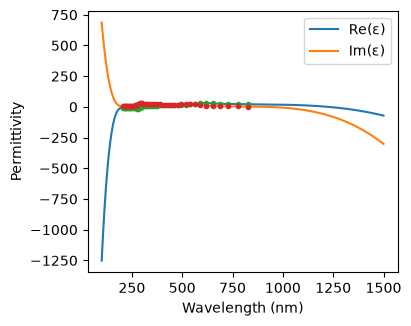

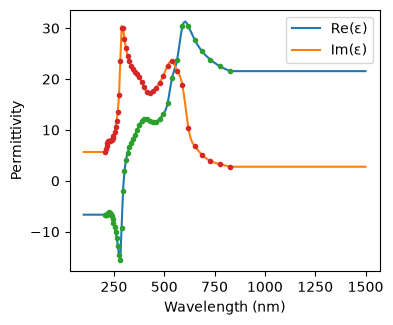

In [5]:
material = Material.from_db('Ge/Aspnes', unit='nm', kind='e')
wavelengths = jp.linspace(100.0, 1500.0, 201)
eps = material.interp(wavelengths, unit='nm', kind='e', interp='cubic', extrap=True)

plt.figure(figsize=(4.0,3.4))
plt.plot(wavelengths, jp.real(eps), label='Re(ε)')
plt.plot(wavelengths, jp.imag(eps), label='Im(ε)')
plt.plot(material.f, material.re, '.')
plt.plot(material.f, material.im, '.')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Permittivity')
plt.legend()
plt.show()

eps = material.interp(wavelengths, unit='nm', kind='e', interp='cubic', extrap=False)

plt.figure(figsize=(4.0,3.4))
plt.plot(wavelengths, jp.real(eps), label='Re(ε)')
plt.plot(wavelengths, jp.imag(eps), label='Im(ε)')
plt.plot(material.f, material.re, '.')
plt.plot(material.f, material.im, '.')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Permittivity')
plt.legend()
plt.show()